# Scoliosis1K: from raw silhouette PNG to .pkl

My notes while learning how OpenGait turns the raw Scoliosis1K frames into .pkl files, which are the input for ScoNet.
I take one sequence from each class (positive, neutral, negative) and follow every step with pictures.

The logic is the same as `datasets/pretreatment.py` in OpenGait, but split into small functions so I can see what each part does.

Where the data comes from:
- The original data is a video of a child walking. The videos are not shared because of privacy.
- The authors ran a segmentation model (PP-HumanSeg v2) on every frame. So the raw data I have is already silhouettes (white person, black background), one PNG per frame.
- This notebook does the next part: PNG frames to one .pkl per sequence.

Run the cells from top to bottom, later cells use variables from earlier cells. Kernel: sconet (Python 3.10).

## 1 · Setup
Import the libraries and set the folders.
- `os`: build paths and make folders
- `glob`: find files with a pattern like `*.png`
- `pickle`: save and load the numpy array as a file
- `cv2` (OpenCV): read and resize images
- `numpy`: images are arrays of numbers
- `matplotlib`: draw the figures

`r"..."` is a raw string, so the Windows backslashes are not read as special characters.
`os.makedirs(..., exist_ok=True)` makes the folder and does not complain if it already exists.
`save_and_show` saves each figure into `output/figures` and shows it.

In [13]:
import os
import glob
import pickle

import cv2
import numpy as np
import matplotlib.pyplot as plt

# folders use in and out
OPENGAIT = r"C:\Users\ASUS\.vscode\OpenGait"
RAW_ROOT = os.path.join(OPENGAIT, "datasets", "Scoliosis1K", "Scoliosis1K-sil-raw")
OFFICIAL_PKL_ROOT = os.path.join(OPENGAIT, "datasets", "Scoliosis1K", "Scoliosis1K-sil-pkl")
OUT_ROOT = os.path.join(OPENGAIT, "self_learning", "raw_to_pkl", "output")
PKL_ROOT = os.path.join(OUT_ROOT, "pkl")
FIG_DIR = os.path.join(OUT_ROOT, "figures")
os.makedirs(PKL_ROOT, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

IMG_SIZE = 64
CLASSES = ["positive", "neutral", "negative"]


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()

## 2 · Pick one in every class
The folder path is the label, there is no separate label file:

`Scoliosis1K-sil-raw \ subject \ class \ view \ 00000.png, 00001.png, ...`

- `glob` with the pattern `*\positive\*` finds every positive sequence. `sorted` makes the order fixed, so `[0]` always gives the same one.
- `basename` gives the last part of a path, `dirname` goes one folder up. That is how I get the subject id and the view.
- The frames must be sorted so they stay in time order. Without sorting the walk could get shuffled.
- `samples` is a dictionary, for example `samples["positive"]["frames"]` is the list of frame paths.

Chosen: positive 00000, neutral 01293, negative 00493. All view 000_180, 300 frames each.

In [14]:
samples = {}
for cls in CLASSES:
    seq_dirs = sorted(glob.glob(os.path.join(RAW_ROOT, "*", cls, "*")))
    seq_dir = seq_dirs[0]

    subject_id = os.path.basename(os.path.dirname(os.path.dirname(seq_dir)))
    view = os.path.basename(seq_dir)
    frame_paths = sorted(glob.glob(os.path.join(seq_dir, "*.png")))

    samples[cls] = {"dir": seq_dir, "subject": subject_id, "view": view, "frames": frame_paths}
    print(f"{cls:>8}: {len(seq_dirs):3d} sequences in this class -> chose subject {subject_id}, "
          f"view {view}, {len(frame_paths)} frames")

positive: 493 sequences in this class -> chose subject 00000, view 000_180, 300 frames
 neutral: 200 sequences in this class -> chose subject 01293, view 000_180, 300 frames
negative: 800 sequences in this class -> chose subject 00493, view 000_180, 300 frames


## 3 · Array in images
A grayscale image is a 2D array with shape `(height, width)`. Height comes first.
- 0 is black (background), 255 is white (body). Values in between are at the body edges, because the segmentation model is not sure there.
- The raw PNGs are already cropped around the person, but every frame has a different size (the child is closer or further from the camera).
- Frames with different sizes cannot be stacked into one array, that is why preprocessing is needed.
- `np.linspace(0, 299, 6)` picks 6 frames spread over the whole walk.

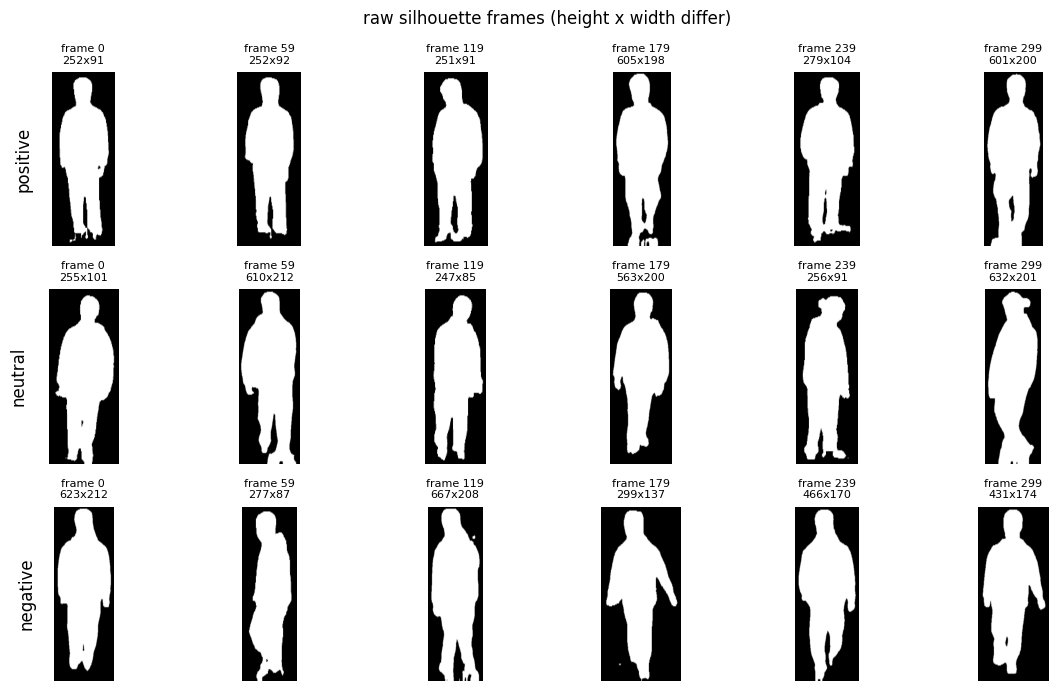

positive: height 249-661, width 77-224
 neutral: height 244-648, width 80-214
negative: height 277-712, width 85-922


In [15]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 7))
for row, cls in enumerate(CLASSES):
    paths = samples[cls]["frames"]
    picks = np.linspace(0, len(paths) - 1, 6).astype(int)
    for col, i in enumerate(picks):
        img = cv2.imread(paths[i], cv2.IMREAD_GRAYSCALE)
        ax = axes[row, col]
        ax.imshow(img, cmap="gray")
        ax.set_title(f"frame {i}\n{img.shape[0]}x{img.shape[1]}", fontsize=8)
        ax.axis("off")
    axes[row, 0].text(-0.3, 0.5, cls, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=12)
fig.suptitle("raw silhouette frames (height x width differ)")
save_and_show(fig, "step2_raw_frames.png")

for cls in CLASSES:
    shapes = [cv2.imread(p, cv2.IMREAD_GRAYSCALE).shape for p in samples[cls]["frames"]]
    hs, ws = [s[0] for s in shapes], [s[1] for s in shapes]
    print(f"{cls:>8}: height {min(hs)}-{max(hs)}, width {min(ws)}-{max(ws)}")

## 4 · Empty check + crop top/bottom
`is_empty` adds all pixel values. If the total is 10000 or less (about 40 white pixels) there is almost no person in the frame, so I drop it.
It is only a quality filter. Deciding which pixel belongs to the person was already done by the segmentation model.

`crop_top_bottom` removes the black rows above the head and below the feet.
- `sum(axis=1)` gives one total per row. `!= 0` turns it into True/False: is there body in this row.
- `argmax()` gives the first True, the top of the head.
- `cumsum().argmax()` gives the last True, the bottom of the feet. The running total stops growing after the last body row.
- `img[y_top : y_btm + 1, :]` keeps those rows. `+1` because the end of a slice is not included.

For the raw Scoliosis1K frames only a few rows are removed (0 to 41 in the neutral sample), because the PNGs are already cropped.
In other datasets like CASIA-B the raw frame is the full camera image, there this step removes a lot.

In [16]:
def is_empty(img):
    return img.sum() <= 10000


def crop_top_bottom(img):
    row_sum = img.sum(axis=1)
    has_pixels = row_sum != 0
    y_top = has_pixels.argmax()
    y_btm = has_pixels.cumsum().argmax()
    return img[y_top: y_btm + 1, :], y_top, y_btm


img = cv2.imread(samples["positive"]["frames"][150], cv2.IMREAD_GRAYSCALE)
cropped, y_top, y_btm = crop_top_bottom(img)
print("sum:", img.sum(), "-> empty?", is_empty(img))
print("original", img.shape, "-> body rows", y_top, "to", y_btm, "-> cropped", cropped.shape)

sum: 4466339 -> empty? False
original (315, 119) -> body rows 9 to 302 -> cropped (294, 119)


## 5 · Resize to height 64
Every frame needs the same height so all frames and all people can be compared and stacked.
- `ratio = width / height`, new width = `int(64 * ratio)`. Height and width shrink by the same factor, so the body is not stretched.
- `cv2.resize` wants `(width, height)` but `img.shape` is `(height, width)`. Easy to mix up.
- `INTER_CUBIC` is a smooth resize that makes soft grey edges. OpenGait uses this one.

Example from the neutral frame: cropped 272 x 110, ratio 0.404, `int(64 * 0.404)` = 25, so the result is 64 x 25.

In [17]:
def resize_to_height(img, height=IMG_SIZE):
    ratio = img.shape[1] / img.shape[0]
    new_width = int(height * ratio)
    return cv2.resize(img, (new_width, height), interpolation=cv2.INTER_CUBIC)

### Experiment: correct resize vs three wrong ones
- swapped: width and height in the wrong order, the person ends up flat and wide.
- stretched: forced to 64 x 64, the body becomes much wider than it really is.
- nearest: only copies existing pixels and does not make new in-between values, so it has fewer unique values and blocky edges.

ratio 0.405 | good (64, 25) | swap (25, 64) | stretch (64, 64)
unique values -> cubic: 51  nearest: 29


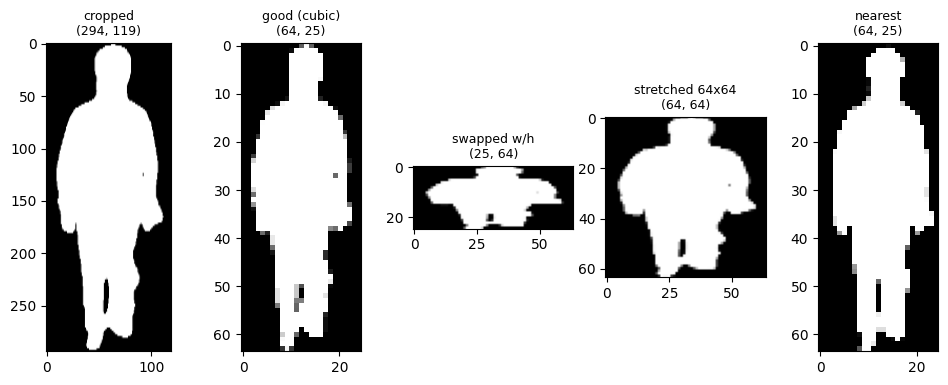

In [18]:
ratio = cropped.shape[1] / cropped.shape[0]
good = resize_to_height(cropped)
swap = cv2.resize(cropped, (64, good.shape[1]), interpolation=cv2.INTER_CUBIC)
stretch = cv2.resize(cropped, (64, 64), interpolation=cv2.INTER_CUBIC)
nearest = cv2.resize(cropped, (good.shape[1], 64), interpolation=cv2.INTER_NEAREST)

print("ratio", round(ratio, 3), "| good", good.shape, "| swap", swap.shape, "| stretch", stretch.shape)
print("unique values -> cubic:", len(np.unique(good)), " nearest:", len(np.unique(nearest)))

fig, ax = plt.subplots(1, 5, figsize=(12, 4))
for a, im, t in zip(ax, [cropped, good, swap, stretch, nearest],
                    ["cropped", "good (cubic)", "swapped w/h", "stretched 64x64", "nearest"]):
    a.imshow(im, cmap="gray")
    a.set_title(f"{t}\n{im.shape}", fontsize=9)
plt.show()

## 6 · Find the body centre + cut a 64 wide window
`find_x_center`
- `sum(axis=0)` is how much body is in each column, `cumsum()` is the running total from left to right.
- The centre is the first column where the running total passes half of all body pixels. Half of the body is left of it, half is right.
- This stays on the trunk even when an arm or a leg sticks out. The plain middle of the image would move.

`cut_window`
- Take 32 columns left and 32 columns right of the centre, so 64 wide.
- After resizing the body is only about 25 wide, so the window goes past the edges. Then 32 black columns are added on both sides (`np.zeros` + `np.concatenate`), and `left`/`right` move +32 because everything shifted 32 to the right.
- Example: width 25, centre 12, left = 12 - 32 = -20 (outside the image). After padding the canvas is 25 + 64 = 89 wide and the window is 12 to 76, which is 64 columns.
- `astype("uint8")` makes the values whole numbers 0-255 again, the zero padding had made them float.

In [19]:
def find_x_center(img):
    col_cumsum = img.sum(axis=0).cumsum()
    half_total = img.sum() / 2
    for idx, csum in enumerate(col_cumsum):
        if csum > half_total:
            return idx
    return None


def cut_window(img, x_center, size=IMG_SIZE):
    half = size // 2
    left, right = x_center - half, x_center + half
    padded = False
    if left <= 0 or right >= img.shape[1]:
        left += half
        right += half
        pad = np.zeros((img.shape[0], half))
        img = np.concatenate([pad, img, pad], axis=1)
        padded = True
    return img[:, left:right].astype("uint8"), left, right, padded, img

### Experiment: centre, padded canvas and window
Green line is the centre. Yellow lines are the 64 column window on the padded canvas.

resized width 25 | centre 12 | raw left -20 | padded? True | canvas (64, 89) | window 12 to 76 | result (64, 64)


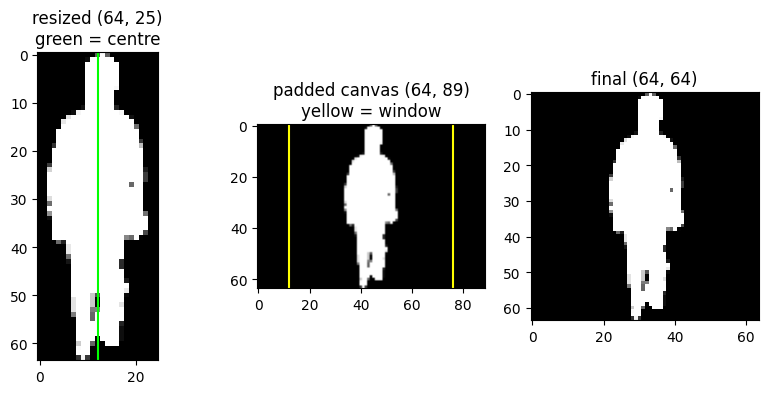

In [20]:
xc = find_x_center(good)
win, left, right, padded, canvas = cut_window(good, xc)
print("resized width", good.shape[1], "| centre", xc, "| raw left", xc - 32,
      "| padded?", padded, "| canvas", canvas.shape, "| window", left, "to", right, "| result", win.shape)

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(good, cmap="gray"); ax[0].axvline(xc, color="lime"); ax[0].set_title(f"resized {good.shape}\ngreen = centre")
ax[1].imshow(canvas, cmap="gray"); ax[1].axvline(left, color="yellow"); ax[1].axvline(right, color="yellow")
ax[1].set_title(f"padded canvas {canvas.shape}\nyellow = window")
ax[2].imshow(win, cmap="gray"); ax[2].set_title(f"final {win.shape}")
plt.show()

## 7 · Merged step
`process_frame` runs everything in order: empty check, crop, resize, centre, window.
- It returns `None` if the frame can not be used (empty, or no centre found). Those frames get skipped later.
- `steps` keeps every in-between result, only for drawing the figure below.
- `if not x_center` rejects `None` and also `0`. That is the same rule as OpenGait.

In the figure: red lines are the first and last body row, green is the centre, and the graph shows where the running total crosses half of the total (dashed line).

In [21]:
def process_frame(img):
    steps = {"original": img}
    if is_empty(img):
        return None, steps
    cropped, y_top, y_btm = crop_top_bottom(img)
    steps.update(cropped=cropped, y_top=y_top, y_btm=y_btm)
    resized = resize_to_height(cropped)
    steps["resized"] = resized
    x_center = find_x_center(resized)
    steps["x_center"] = x_center
    if not x_center:
        return None, steps
    final, left, right, padded, canvas = cut_window(resized, x_center)
    steps.update(final=final, left=left, right=right, padded=padded, canvas=canvas)
    return final, steps

(0) pixel sum = 4466339  -> empty? False
(1) body rows 9 .. 302  -> (315, 119) becomes (294, 119)
(2) resize -> (64, 25)
(3) x centre = column 12
(4) window columns 12 .. 76 (padded: True) -> (64, 64)


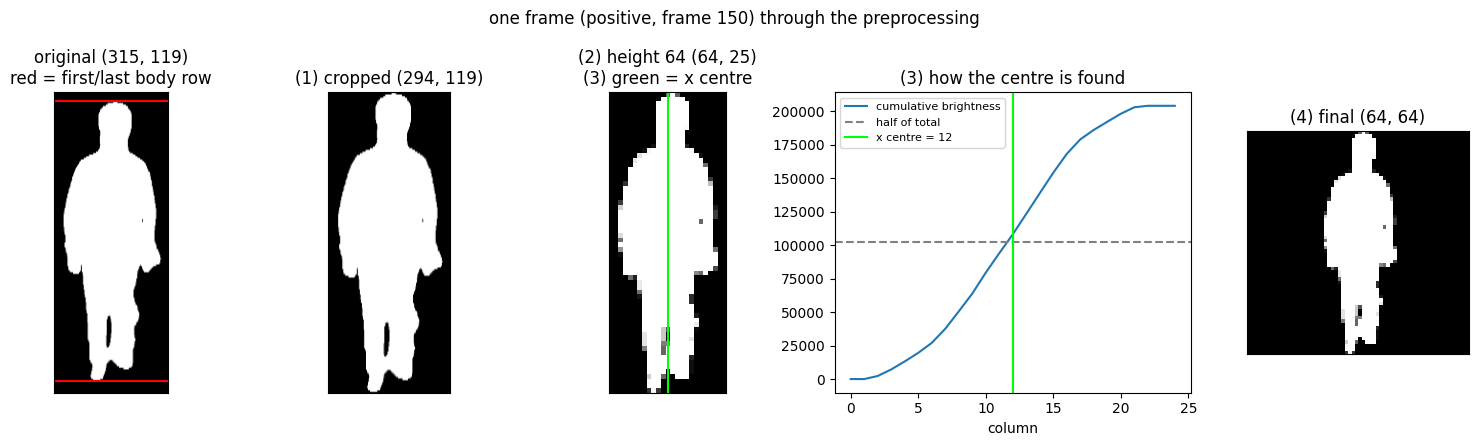

In [22]:
cls = "positive"
frame_idx = len(samples[cls]["frames"]) // 2
img = cv2.imread(samples[cls]["frames"][frame_idx], cv2.IMREAD_GRAYSCALE)
final, s = process_frame(img)

print(f"(0) pixel sum = {img.sum()}  -> empty? {is_empty(img)}")
print(f"(1) body rows {s['y_top']} .. {s['y_btm']}  -> {img.shape} becomes {s['cropped'].shape}")
print(f"(2) resize -> {s['resized'].shape}")
print(f"(3) x centre = column {s['x_center']}")
print(f"(4) window columns {s['left']} .. {s['right']} (padded: {s['padded']}) -> {final.shape}")

fig, axes = plt.subplots(1, 5, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1, 1, 1.6, 1]})
axes[0].imshow(s["original"], cmap="gray")
axes[0].axhline(s["y_top"], color="red")
axes[0].axhline(s["y_btm"], color="red")
axes[0].set_title(f"original {s['original'].shape}\nred = first/last body row")
axes[1].imshow(s["cropped"], cmap="gray")
axes[1].set_title(f"(1) cropped {s['cropped'].shape}")
axes[2].imshow(s["resized"], cmap="gray")
axes[2].axvline(s["x_center"], color="lime")
axes[2].set_title(f"(2) height 64 {s['resized'].shape}\n(3) green = x centre")
col_sum = s["resized"].sum(axis=0)
axes[3].plot(col_sum.cumsum(), label="cumulative brightness")
axes[3].axhline(s["resized"].sum() / 2, color="gray", ls="--", label="half of total")
axes[3].axvline(s["x_center"], color="lime", label=f"x centre = {s['x_center']}")
axes[3].set_xlabel("column")
axes[3].legend(fontsize=8)
axes[3].set_title("(3) how the centre is found")
axes[4].imshow(s["final"], cmap="gray")
axes[4].set_title(f"(4) final {s['final'].shape}")
for ax in (axes[0], axes[1], axes[2], axes[4]):
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"one frame ({cls}, frame {frame_idx}) through the preprocessing")
save_and_show(fig, "step3_one_frame.png")

## 8 · Save one .pkl per sequence
- Loop over all 300 frames in time order, keep the good ones and remember which ones were skipped.
- `np.asarray(frames)` turns a list of 300 arrays of 64 x 64 into one array with shape `(300, 64, 64)`. This only works because every frame now has the same size.
- `pickle.dump` saves the array as it is. `"wb"` means write binary, and `with` closes the file by itself.
- Same folder layout as the official data (`subject\class\view\view.pkl`), so OpenGait can read it.

A .pkl is just the saved numpy array. Loading one file is much faster than opening 300 PNGs every time during training.

In [23]:
for cls in CLASSES:
    info = samples[cls]
    frames, skipped = [], []
    for i, path in enumerate(info["frames"]):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        final, _ = process_frame(img)
        if final is None:
            skipped.append(i)
        else:
            frames.append(final)

    sequence = np.asarray(frames)
    out_dir = os.path.join(PKL_ROOT, info["subject"], cls, info["view"])
    os.makedirs(out_dir, exist_ok=True)
    pkl_path = os.path.join(out_dir, f"{info['view']}.pkl")
    with open(pkl_path, "wb") as f:
        pickle.dump(sequence, f)

    info["pkl"] = pkl_path
    print(f"{cls:>8}: {len(info['frames'])} PNGs -> kept {len(frames)}, skipped {len(skipped)} {skipped[:10]}")
    print(f"          saved {sequence.shape} {sequence.dtype} -> {pkl_path}")

positive: 300 PNGs -> kept 300, skipped 0 []
          saved (300, 64, 64) uint8 -> C:\Users\ASUS\.vscode\OpenGait\self_learning\raw_to_pkl\output\pkl\00000\positive\000_180\000_180.pkl
 neutral: 300 PNGs -> kept 300, skipped 0 []
          saved (300, 64, 64) uint8 -> C:\Users\ASUS\.vscode\OpenGait\self_learning\raw_to_pkl\output\pkl\01293\neutral\000_180\000_180.pkl
negative: 300 PNGs -> kept 300, skipped 0 []
          saved (300, 64, 64) uint8 -> C:\Users\ASUS\.vscode\OpenGait\self_learning\raw_to_pkl\output\pkl\00493\negative\000_180\000_180.pkl


## 9 · Compare with the official .pkl
If my code does the same as OpenGait, my arrays should be the same as the ones in `Scoliosis1K-sil-pkl`.
`.astype(int)` before subtracting, because `uint8` can not be negative (3 - 5 would become 254 instead of -2).

In [24]:
for cls in CLASSES:
    info = samples[cls]
    with open(info["pkl"], "rb") as f:
        ours = pickle.load(f)
    official_path = os.path.join(OFFICIAL_PKL_ROOT, info["subject"], cls, info["view"], f"{info['view']}.pkl")
    with open(official_path, "rb") as f:
        official = pickle.load(f)

    if ours.shape != official.shape:
        print(f"{cls:>8}: shape differs! ours {ours.shape} vs official {official.shape}")
        continue
    diff = np.abs(ours.astype(int) - official.astype(int))
    print(f"{cls:>8}: shape {ours.shape} | identical: {np.array_equal(ours, official)} | "
          f"pixels that differ: {(diff > 0).mean() * 100:.3f}% | max difference: {diff.max()}")

positive: shape (300, 64, 64) | identical: True | pixels that differ: 0.000% | max difference: 0
 neutral: shape (300, 64, 64) | identical: True | pixels that differ: 0.000% | max difference: 0
negative: shape (300, 64, 64) | identical: False | pixels that differ: 9.143% | max difference: 255


### My result
| class | identical | pixels that differ |
|---|---|---|
| positive | True | 0% |
| neutral | True | 0% |
| negative | False | 9.1% (max difference 255) |

What I found about negative:
- Positive and neutral match pixel for pixel, so the preprocessing code is correct.
- I checked 40 random sequences per class. Positive 0/40 different, neutral 0/40, negative 40/40. So it is every negative subject, not only 00493.
- The silhouettes themselves look different. Frame 150 of 00493: the raw version is wider and rounder, the official pkl is slimmer with a clear head.
- Changing the resize method or thresholding the image does not fix it.
- So the negative raw PNGs and the negative pkl were made from different silhouettes. Both came from the authors by email.

What I do with this:
- For training and reproducing the paper I use the official `Scoliosis1K-sil-pkl`, because the published results come from that.
- I don't rebuild the negative class from raw. If one class has a different segmentation than the others, the model could learn the segmentation style instead of scoliosis.

mine    : (300, 64, 64) uint8
official: (300, 64, 64) uint8


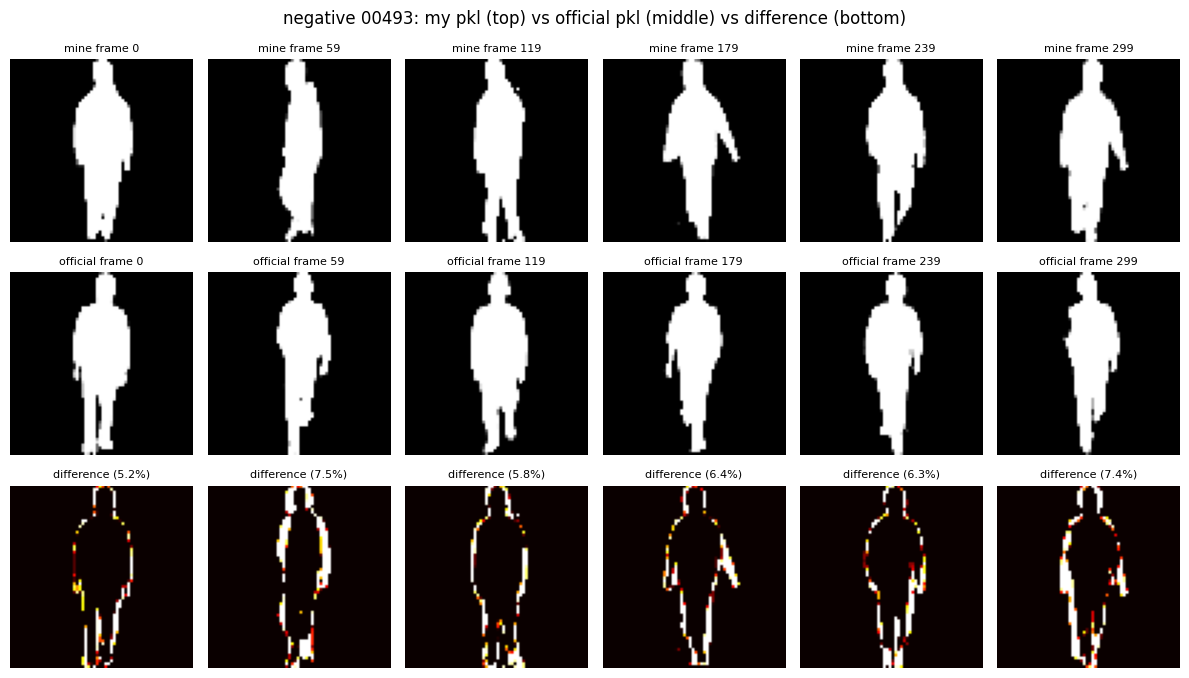

In [26]:
mine_path = r"C:\Users\ASUS\.vscode\OpenGait\self_learning\raw_to_pkl\output\pkl\00493\negative\000_180\000_180.pkl"
official_path = r"C:\Users\ASUS\.vscode\OpenGait\datasets\Scoliosis1K\Scoliosis1K-sil-pkl\00493\negative\000_180\000_180.pkl"

with open(mine_path, "rb") as f:
    mine = pickle.load(f)
with open(official_path, "rb") as f:
    official = pickle.load(f)

print("mine    :", mine.shape, mine.dtype)
print("official:", official.shape, official.dtype)

frames = np.linspace(0, len(mine) - 1, 6).astype(int)

fig, axes = plt.subplots(3, len(frames), figsize=(12, 7))
for col, i in enumerate(frames):
    diff = np.abs(mine[i].astype(int) - official[i].astype(int))

    axes[0, col].imshow(mine[i], cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"mine frame {i}", fontsize=8)

    axes[1, col].imshow(official[i], cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"official frame {i}", fontsize=8)

    axes[2, col].imshow(diff, cmap="hot", vmin=0, vmax=255)
    axes[2, col].set_title(f"difference ({(diff > 0).mean() * 100:.1f}%)", fontsize=8)

for ax in axes.flat:
    ax.axis("off")
fig.suptitle("negative 00493: my pkl (top) vs official pkl (middle) vs difference (bottom)")
plt.tight_layout()
plt.show()


## 10 · What the model actually receives
When ScoNet loads a .pkl it does one more small step (`BaseSilCuttingTransform` in OpenGait):
- cut 10 columns on the left and 10 on the right, so 64 x 64 becomes 64 x 44 (those columns are almost always black)
- divide by 255, so the values are 0 to 1 (neural networks train better with small numbers)

Extra pictures, not part of ScoNet, only to understand the data:
- average of all frames (Gait Energy Image): parts that don't move much (head, trunk) look solid, the legs look blurry
- left-right asymmetry: flip the average image (`[:, ::-1]`) and subtract it. Red/blue where left and right are different. This is not a diagnosis.

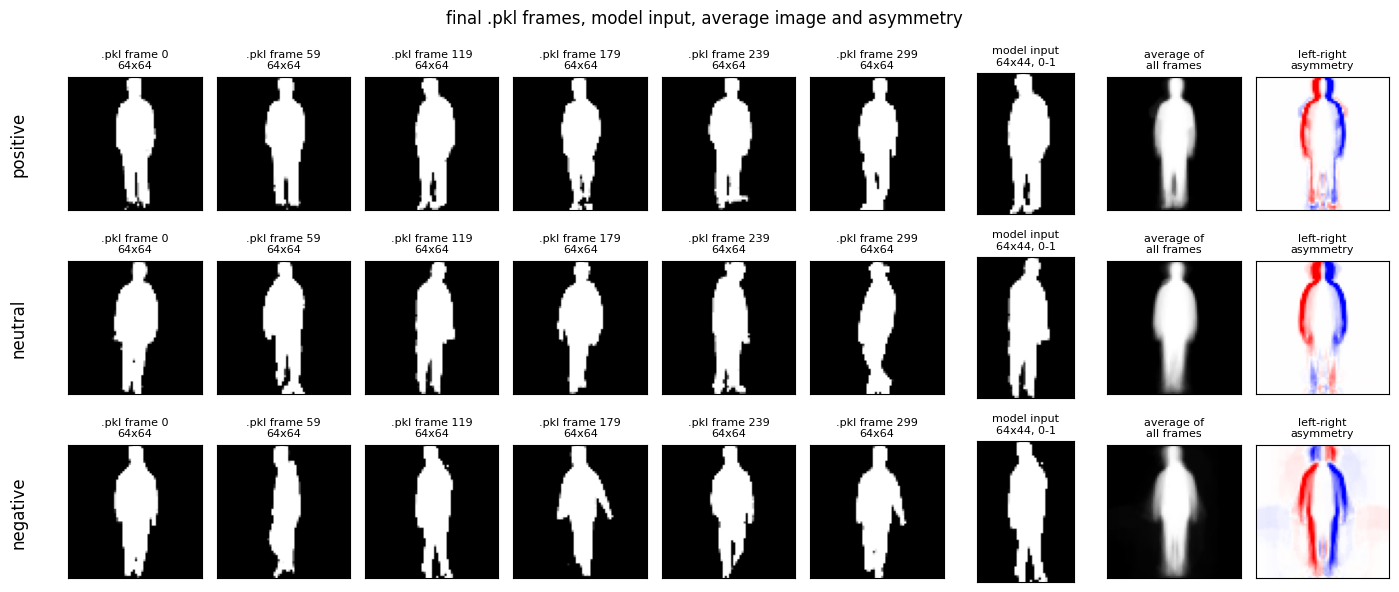

summary
positive: subject 00000 -> .pkl (300, 64, 64) -> model input (300, 64, 44)
 neutral: subject 01293 -> .pkl (300, 64, 64) -> model input (300, 64, 44)
negative: subject 00493 -> .pkl (300, 64, 64) -> model input (300, 64, 44)


In [25]:
def model_input(sequence):
    cut = int(sequence.shape[-1] // 64) * 10
    return sequence[..., cut:-cut] / 255.0


fig, axes = plt.subplots(len(CLASSES), 9, figsize=(14, 6))
for row, cls in enumerate(CLASSES):
    with open(samples[cls]["pkl"], "rb") as f:
        seq = pickle.load(f)
    x = model_input(seq)
    picks = np.linspace(0, len(seq) - 1, 6).astype(int)
    for col, i in enumerate(picks):
        axes[row, col].imshow(seq[i], cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f".pkl frame {i}\n64x64", fontsize=8)
    axes[row, 6].imshow(x[picks[2]], cmap="gray", vmin=0, vmax=1)
    axes[row, 6].set_title(f"model input\n{x.shape[1]}x{x.shape[2]}, 0-1", fontsize=8)
    axes[row, 7].imshow(seq.mean(axis=0), cmap="gray")
    axes[row, 7].set_title("average of\nall frames", fontsize=8)
    axes[row, 8].imshow(seq.mean(axis=0)[:, ::-1] - seq.mean(axis=0), cmap="bwr", vmin=-80, vmax=80)
    axes[row, 8].set_title("left-right\nasymmetry", fontsize=8)
    axes[row, 0].text(-0.3, 0.5, cls, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=12)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("final .pkl frames, model input, average image and asymmetry")
save_and_show(fig, "step6_final.png")

print("summary")
for cls in CLASSES:
    with open(samples[cls]["pkl"], "rb") as f:
        seq = pickle.load(f)
    print(f"{cls:>8}: subject {samples[cls]['subject']} -> .pkl {seq.shape} -> model input {model_input(seq).shape}")

## Summary
raw PNG (different sizes) -> drop empty frames -> crop top/bottom -> height 64 -> find centre -> 64 wide window -> stack all frames -> .pkl `(T, 64, 64)` -> in training: cut to 64 x 44 and divide by 255 -> ScoNet